# Лабораторная работа № 7
## Отбор признаков

**Набор данных:** `weatherAUS` после очистки и масштабирования в предыдущих работах.  
**Цель:** сравнить методы отбора, уменьшить число количественных признаков, сохранить исходные категориальные данные и подготовить итоговые train/test-выборки.

Используются `weatherAUS_train_notencoded_scaled.csv` и `weatherAUS_test_notencoded_scaled.csv` из ZIP-архива в репозитории `OA`. Количественные признаки уже масштабированы, категориальные столбцы и цель сохранены в исходном виде. Параметры масштабирования повторно не рассчитываются.

Численные методы отбора применяются к количественным входам. Категориальные входы анализируются отдельно и сохраняются без кодирования, дата остаётся служебным столбцом. Целевая переменная `ДождьЗавтра` не участвует в отборе как входной признак.

# 1. Теоретическая часть

### 1. Что понимается под отбором признаков и чем он отличается от очистки и масштабирования?

Отбор признаков - выбор подмножества существующих входных переменных для последующего обучения модели. Он уменьшает число столбцов, но не изменяет значения сохранённых признаков и не должен менять число наблюдений.

Очистка направлена на качество данных: обработку пропусков, дубликатов, недопустимых значений и ошибок. Масштабирование меняет числовое представление измерений, чтобы сопоставить их масштабы. Например, давление и температура сначала очищаются, затем стандартизуются, после чего решается, нужны ли модели все измерения этих величин. Отбор не равен созданию новых признаков: PCA строит новые компоненты, а селектор оставляет часть исходных колонок.

### 2. Почему отбор выполняется после масштабирования?

В данной последовательности работ масштабирование уже выполнено в шестой лабораторной. Оно важно для RFE на линейной модели и L1-регуляризации, поскольку размер коэффициентов и действие штрафа зависят от единиц измерения. После стандартизации сравнение коэффициентов становится более осмысленным.

Стандартизованные значения могут быть отрицательными, что допустимо для применяемых методов. Критерий `chi2` из `sklearn.feature_selection` не применяем к этим количественным данным. Для категорий ниже используется отдельный критерий независимости над таблицами неотрицательных частот, а не над стандартизованными измерениями.

### 3. Какие проблемы возникают при использовании всех признаков?

Избыточные входы увеличивают память и время вычислений, усложняют объяснение модели и могут усиливать переобучение. Сильно коррелирующие измерения частично повторяют информацию и способны сделать коэффициенты линейной модели неустойчивыми. В пространстве большой размерности сложнее применять методы, основанные на расстояниях.

Однако большое число признаков само по себе не означает плохого качества. Иногда два похожих измерения полезны совместно: разность давления утром и днём может содержать информацию, которой нет в одном измерении. Поэтому удаление требует обоснования, а не только стремления сделать таблицу меньше.

### 4. Какие группы методов используются?

| Группа | Общий принцип | Пример | Основное ограничение |
|---|---|---|---|
| Фильтрационные | Вычисляют статистические характеристики без повторного обучения итогового классификатора | Корреляция, F-критерий, взаимная информация | Одномерные оценки могут не учитывать взаимодействия |
| Методы-обёртки | Сравнивают меняющиеся наборы входов с помощью модели | RFE | Требуют нескольких обучений и зависят от модели |
| Встроенные | Выполняют отбор в процессе обучения | Логистическая регрессия с L1 | Зависят от регуляризации и структуры данных |


RFE рекурсивно исключает входы с наименьшими по модулю коэффициентами и переобучает модель. L1-регуляризация может занулять коэффициенты, тогда как L2 обычно только уменьшает их и сама по себе не выполняет точный отбор. Для бинарной задачи применяется логистическая регрессия с L1, а не регрессионный Lasso. Чем меньше параметр `C`, тем сильнее регуляризация.

F-критерий оценивает различия средних значений признака между классами относительно внутриклассового разброса. Взаимная информация характеризует зависимость и способна обнаруживать не только линейную связь. Эти оценки не являются точностью классификатора.

### 5. Почему отбор важен перед моделированием?

Отбор помогает получить компактную и понятную структуру входов. Он может уменьшить затраты и снизить влияние избыточных переменных, но не гарантирует улучшения прогноза. Один набор не обязан быть лучшим для логистической регрессии, деревьев и других моделей одновременно.

Селектор обучают только на train, затем одинаковый набор колонок применяют к train и test. При подборе параметров по качеству нужна внутренняя проверка, причём масштабирование и отбор должны обучаться внутри каждого разбиения. Финальный test не используют для выбора метода.

В этой работе сравниваются состав и размерность выборок при заранее заданных параметрах. Итоговый бюджет - десять количественных входов. Категории сохраняются без кодирования и без автоматического исключения, поэтому итоговая таблица остаётся смешанной. Перед обычной численной моделью потребуется обработка текстовых входов, альтернативой служит модель с нативной поддержкой категорий. Для даты решение принимается отдельно.

# 2. Практическая часть
## Подключение библиотек

Подключим средства работы с таблицами, архивами, графиками и методами отбора. Для воспроизводимости зафиксируем случайное состояние. Предупреждения библиотек не отключаем.

In [ ]:
import subprocess
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown
from sklearn.feature_selection import (
    mutual_info_classif, SelectKBest, f_classif, RFE, SelectFromModel
)
from sklearn.linear_model import LogisticRegression

REPO_DIR = Path("OA")
REPO_URL = "https://github.com/LoreOfMetal11/OA.git"
DATA_DIR = Path("data_prepared")
TARGET_COL = "ДождьЗавтра"
DATE_COL = "Дата"
RANDOM_STATE = 42
FILE_NAMES = {
    "train": "weatherAUS_train_notencoded_scaled.csv",
    "test": "weatherAUS_test_notencoded_scaled.csv",
}

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")
plt.style.use("ggplot")

## Загрузка выборок из ZIP-архива

Сначала проверим готовые CSV в `data_prepared`, рабочей папке и репозитории. Если локальной папки `OA` нет, клонируем репозиторий. Затем найдём ZIP-архивы и извлечём из них только два нужных CSV. Имя самого архива не задаётся: нужные файлы определяются по именам внутри него, включая вложенные папки.

Текстовые значения не преобразуются, данные повторно не масштабируются. Существующий локальный репозиторий автоматически не обновляется. Если после публикации архива осталась старая локальная копия `OA`, её нужно предварительно обновить либо положить архив в рабочую папку.

In [ ]:
DATA_DIR.mkdir(exist_ok=True)

def find_csv(filename):
    for folder in [DATA_DIR, Path("."), REPO_DIR]:
        direct = folder / filename
        if direct.is_file():
            return direct
    if REPO_DIR.is_dir():
        matches = sorted(REPO_DIR.rglob(filename))
        if matches:
            return matches[0]
    return None

paths = {part: find_csv(name) for part, name in FILE_NAMES.items()}
if any(path is None for path in paths.values()) and not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True
    )
    paths = {part: find_csv(name) for part, name in FILE_NAMES.items()}

archives = sorted({
    path for folder in [Path("."), DATA_DIR] for path in folder.glob("*")
    if path.is_file() and path.suffix.lower() == ".zip"
} | {
    path for path in REPO_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() == ".zip"
})

for archive_path in archives:
    if all(path is not None for path in paths.values()):
        break
    if not zipfile.is_zipfile(archive_path):
        continue
    with zipfile.ZipFile(archive_path) as archive:
        for part, filename in FILE_NAMES.items():
            if paths[part] is not None:
                continue
            matches = [member for member in archive.infolist()
                       if not member.is_dir()
                       and "__MACOSX" not in member.filename
                       and Path(member.filename.replace("\\", "/")).name in [filename, Path(filename).stem]]
            if not matches:
                continue
            if len(matches) > 1:
                raise ValueError(f"В {archive_path} несколько файлов {filename}, оставьте нужную пару CSV в data_prepared.")
            destination = DATA_DIR / filename
            with archive.open(matches[0]) as source, destination.open("wb") as target:
                shutil.copyfileobj(source, target)
            paths[part] = destination
            print(f"Извлечён {filename} из {archive_path}")

missing = [FILE_NAMES[part] for part, path in paths.items() if path is None]
if missing:
    found_archives = ", ".join(str(path) for path in archives) or "нет"
    raise FileNotFoundError(
        "Не найдены: " + ", ".join(missing) +
        ". Проверенные ZIP: " + found_archives +
        ". Обновите локальную папку OA или положите ZIP с выборками в рабочую папку."
    )

train_scaled = pd.read_csv(paths["train"])
test_scaled = pd.read_csv(paths["test"])
print("Train-файл:", paths["train"])
print("Test-файл: ", paths["test"])
print("Размер train:", train_scaled.shape)
print("Размер test: ", test_scaled.shape)
display(train_scaled.head())

Train-файл: data_prepared/weatherAUS_train_notencoded_scaled.csv
Test-файл:  data_prepared/weatherAUS_test_notencoded_scaled.csv
Размер train: (113752, 23)
Размер test:  (28438, 23)


,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,НаправлениеВетра15,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15,ДождьСегодня,ДождьЗавтра
0,2007-11-02,Canberra,0.2854,0.5172,0.1406,-0.2552,0.5931,ENE,-0.0699,E,W,-1.1273,-0.1860,0.5813,-0.7495,-0.7751,-1.0249,0.1332,-0.7303,0.0845,0.5861,Yes,Yes
1,2007-11-03,Canberra,0.2386,0.0257,0.1406,0.1257,-1.6719,NW,3.4203,N,NNE,-0.9016,-1.4454,0.6860,0.8468,-1.2040,-1.2043,1.3729,1.0367,-0.2376,-0.2100,Yes,Yes
2,2007-11-04,Canberra,0.1763,-1.0837,4.3455,0.5066,0.3807,NW,1.0682,WNW,W,1.8074,0.6154,-0.3605,0.2180,-1.7957,-1.2342,-1.1066,1.0367,-0.5290,-1.0928,Yes,Yes
3,2007-11-05,Canberra,-0.7127,-0.9995,0.0476,0.0713,0.9116,SSE,0.7647,SSE,ESE,0.6786,1.0734,-0.0466,-0.1206,0.0977,0.4847,0.9597,1.0367,-0.8971,-0.9047,Yes,No
4,2007-11-06,Canberra,-0.9310,-0.8871,-0.2776,0.1257,0.0622,SE,0.3095,SE,E,0.6786,0.6154,0.0581,0.2663,0.9112,0.9630,0.9597,0.1532,-0.9278,-0.9915,No,No


## Определение типов признаков

Отделим количественные входы, категориальные столбцы, дату и цель. Дата нужна для сохранения исходной структуры и дальнейшего анализа, но в текущие численные селекторы не передаётся.

In [ ]:
assert TARGET_COL in train_scaled.columns
assert DATE_COL in train_scaled.columns
assert list(train_scaled.columns) == list(test_scaled.columns)

NUMERIC_COLS = [col for col in train_scaled.select_dtypes(include="number").columns
                if col not in [TARGET_COL, DATE_COL]]
CATEGORY_COLS = [col for col in train_scaled.columns
                if col not in NUMERIC_COLS + [DATE_COL, TARGET_COL]]

X_train = train_scaled[NUMERIC_COLS].copy()
X_test = test_scaled[NUMERIC_COLS].copy()
y_train = train_scaled[TARGET_COL].copy()
y_test = test_scaled[TARGET_COL].copy()

roles = pd.DataFrame({
    "Столбец": train_scaled.columns,
    "Тип": train_scaled.dtypes.astype(str).to_numpy(),
})
roles["Роль"] = roles["Столбец"].map(
    lambda col: "Целевая переменная" if col == TARGET_COL
    else "Служебная дата" if col == DATE_COL
    else "Категориальный вход" if col in CATEGORY_COLS
    else "Количественный вход"
)
display(roles)
print("Количественных входов:", len(NUMERIC_COLS))
print("Категориальных входов:", len(CATEGORY_COLS))

,Столбец,Тип,Роль
0,Дата,object,Служебная дата
1,Место,object,Категориальный вход
2,МинТемпература,float64,Количественный вход
3,МаксТемпература,float64,Количественный вход
4,Осадки,float64,Количественный вход
5,Испарение,float64,Количественный вход
6,СолнечныеЧасы,float64,Количественный вход
7,НаправлениеПорываВетра,object,Категориальный вход
8,СкоростьПорываВетра,float64,Количественный вход
9,НаправлениеВетра9,object,Категориальный вход


Количественных входов: 16
Категориальных входов: 5


Полученная таблица ролей разделяет все 23 столбца на четыре непересекающиеся группы:

- **16 количественных входов**: температуры, осадки, испарение, солнечные часы, скорости ветра, влажность, давление и облачность,
- **5 категориальных входов**: `Место`, `НаправлениеПорываВетра`, `НаправлениеВетра9`, `НаправлениеВетра15`, `ДождьСегодня`,
- **1 служебный столбец** `Дата`,
- **1 целевой столбец** `ДождьЗавтра`.

`X_train` и `X_test` содержат только количественные входы, поскольку F-критерий, RFE и линейная модель работают с числовой матрицей. `y_train` и `y_test` содержат цель. Выделение количественной части не означает удаление категорий из итогового датасета: они остаются в полных таблицах и возвращаются при сборке результата.

Дата не рассматривается как обычная категория с большим числом уникальных значений. Она сохраняется для последующей работы с временем, но не входит в текущие селекторы. Цель также не должна попадать во входы: иначе возникло бы прямое использование ответа для предсказания этого же ответа.

## Проверка исходной масштабированной выборки

Проверим пропуски, конечность количественных значений, метки классов и свойства стандартизации train.

In [ ]:
assert len(NUMERIC_COLS) == 16, "Проверьте, что загружена полная выборка до отбора."
assert len(CATEGORY_COLS) == 5, "Ожидались исходные категориальные входы без кодирования."
assert not train_scaled.isna().any().any()
assert not test_scaled.isna().any().any()
assert X_test.select_dtypes(exclude="number").empty
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert set(y_train.unique()) == {"Yes", "No"}
assert set(y_test.unique()) <= set(y_train.unique())
assert test_scaled[CATEGORY_COLS].select_dtypes(include="number").empty
assert np.allclose(X_train.mean(), 0, atol=1e-7)
assert np.allclose(X_train.std(ddof=0), 1, atol=1e-7)

initial_statistics = pd.DataFrame({
    "Среднее": X_train.mean(),
    "Ст. отклонение": X_train.std(ddof=0),
    "Минимум": X_train.min(),
    "Максимум": X_train.max(),
    "Уникальных значений": X_train.nunique(),
})
display(initial_statistics)
display(y_train.value_counts(normalize=True).rename("Доля класса train").to_frame())

,Среднее,Ст. отклонение,Минимум,Максимум,Уникальных значений
МинТемпература,-0.0000,1.0000,-3.2234,3.0769,697
МаксТемпература,0.0000,1.0000,-3.9344,3.4943,639
Осадки,0.0000,1.0000,-0.2776,42.8170,1039
Испарение,-0.0000,1.0000,-1.4523,37.9973,2792
СолнечныеЧасы,0.0000,1.0000,-2.8398,2.2918,1976
СкоростьПорываВетра,-0.0000,1.0000,-2.5737,7.2140,834
СкоростьВетра9,0.0000,1.0000,-1.5788,13.0947,729
СкоростьВетра15,0.0000,1.0000,-2.1324,7.8283,698
Влажность9,0.0000,1.0000,-3.6048,1.6279,911
Влажность15,0.0000,1.0000,-2.4909,2.3463,908


,Доля класса train
ДождьЗавтра,
No,0.7758
Yes,0.2242


Все проверки завершились без исключений. В обеих частях нет пропусков и бесконечных количественных значений, структура train и test совпадает. Среднее каждого количественного признака на train близко к нулю, а стандартное отклонение с `ddof=0` равно единице в пределах заданной точности. Это соответствует результату StandardScaler из шестой работы.

Отрицательные числа здесь нормальны: они обозначают значения ниже среднего train, а не отрицательные физические осадки или влажность. Максимум признака `Осадки` после стандартизации составляет около **42.8170**, `Испарение` - **37.9973**. Значит, стандартизация не ограничила диапазон и не устранила длинные хвосты распределений. Эти большие значения сами по себе не доказывают ошибку измерений, но при моделировании требуют внимания.

Доли классов различаются: около **77.58% `No`** и **22.42% `Yes`**. Поэтому в последующих работах одна только доля верных ответов может быть недостаточно показательной: модель, часто выбирающая `No`, будет иметь заметную базовую accuracy.

Для отбора по малой дисперсии эти стандартизованные столбцы неудобны: все неконстантные входы уже приведены к единичной дисперсии. Корреляционный критерий позволяет искать избыточность без опоры на исходные единицы измерения. Стандартизация test отдельно не проверяется на точное среднее 0 и отклонение 1, поскольку его параметры должны определяться train.

# 2.1. Базовый уровень
## Корреляционный отбор

Удалим избыточность между количественными входами. Если абсолютная корреляция с уже сохранённым входом превышает 0.90, текущий столбец исключается. Порядок исходных колонок фиксирует выбор представителя. Целевая переменная в матрицу корреляций не входит.

После выбора числовой части соберём полную таблицу с категориями, датой и целью.

In [ ]:
def correlation_filter(frame, threshold=0.90):
    correlation = frame.corr().abs()
    kept, removed = [], []
    for col in frame.columns:
        partners = [other for other in kept if correlation.loc[col, other] > threshold]
        if partners:
            partner = max(partners, key=lambda other: correlation.loc[col, other])
            removed.append({
                "Удалённый признак": col,
                "Сохранённый аналог": partner,
                "Модуль корреляции": correlation.loc[col, partner],
            })
        else:
            kept.append(col)
    return kept, pd.DataFrame(removed, columns=[
        "Удалённый признак", "Сохранённый аналог", "Модуль корреляции"
    ])

def assemble_dataset(source, selected_numeric):
    columns = [col for col in source.columns
               if col in selected_numeric or col in CATEGORY_COLS or col == DATE_COL]
    return source[columns + [TARGET_COL]].copy()

CORRELATION_THRESHOLD = 0.90
corr_features, corr_removed = correlation_filter(X_train, CORRELATION_THRESHOLD)
train_corr = assemble_dataset(train_scaled, corr_features)
test_corr = assemble_dataset(test_scaled, corr_features)
assert 0 < len(corr_features) < len(NUMERIC_COLS)
print("Метод: корреляционный фильтр")
print("Порог:", CORRELATION_THRESHOLD)
print("Числовых признаков до:", len(NUMERIC_COLS))
print("Числовых признаков после:", len(corr_features))
print("Удалено:", len(NUMERIC_COLS) - len(corr_features))
display(corr_removed)
display(train_corr.head())

Метод: корреляционный фильтр
Порог: 0.9
Числовых признаков до: 16
Числовых признаков после: 13
Удалено: 3


,Удалённый признак,Сохранённый аналог,Модуль корреляции
0,Давление15,Давление9,0.9602
1,Температура9,МинТемпература,0.9024
2,Температура15,МаксТемпература,0.9737


,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,НаправлениеВетра15,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Облачность9,Облачность15,ДождьСегодня,ДождьЗавтра
0,2007-11-02,Canberra,0.2854,0.5172,0.1406,-0.2552,0.5931,ENE,-0.0699,E,W,-1.1273,-0.1860,0.5813,-0.7495,-0.7751,0.1332,-0.7303,Yes,Yes
1,2007-11-03,Canberra,0.2386,0.0257,0.1406,0.1257,-1.6719,NW,3.4203,N,NNE,-0.9016,-1.4454,0.6860,0.8468,-1.2040,1.3729,1.0367,Yes,Yes
2,2007-11-04,Canberra,0.1763,-1.0837,4.3455,0.5066,0.3807,NW,1.0682,WNW,W,1.8074,0.6154,-0.3605,0.2180,-1.7957,-1.1066,1.0367,Yes,Yes
3,2007-11-05,Canberra,-0.7127,-0.9995,0.0476,0.0713,0.9116,SSE,0.7647,SSE,ESE,0.6786,1.0734,-0.0466,-0.1206,0.0977,0.9597,1.0367,Yes,No
4,2007-11-06,Canberra,-0.9310,-0.8871,-0.2776,0.1257,0.0622,SE,0.3095,SE,E,0.6786,0.6154,0.0581,0.2663,0.9112,0.9597,0.1532,No,No


Применён **корреляционный фильтр с порогом 0.90**. Из 16 количественных входов сохранено **13**, исключено **3**:

| Удалённый вход | Сохранённый аналог | Модуль корреляции |
|---|---|---|
| `Давление15` | `Давление9` | 0.9602 |
| `Температура9` | `МинТемпература` | 0.9024 |
| `Температура15` | `МаксТемпература` | 0.9737 |

Колонки просматриваются в исходном порядке. При обнаружении сильной связи с уже сохранённым входом текущий столбец исключается. Это простое воспроизводимое правило, но оно не доказывает, что выбранный представитель пары полезнее удалённого.

После сборки полной таблицы остаётся **20 столбцов**: 13 количественных входов, 5 категорий, дата и цель. Количество строк не меняется. Функция `assemble_dataset` переносит все категории и дату из исходной таблицы, а целевой столбец добавляет отдельно.

Селектор определяет структуру только по train, test получает тот же список колонок. Значения выбранных входов не пересчитываются, поэтому они остаются масштабированными.

## Корреляции количественных признаков

Построим матрицу корреляций по train, чтобы увидеть группы похожих измерений.

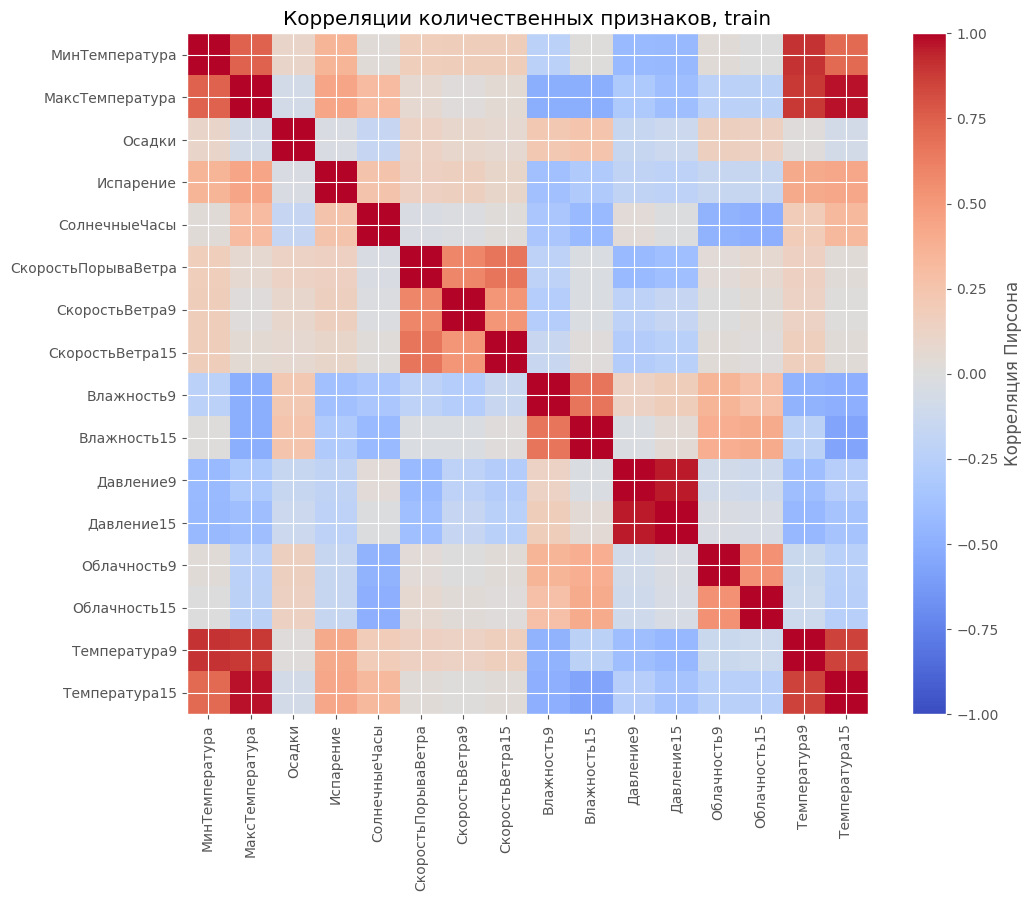

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(X_train.corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC_COLS)), labels=NUMERIC_COLS, rotation=90)
ax.set_yticks(range(len(NUMERIC_COLS)), labels=NUMERIC_COLS)
ax.set_title("Корреляции количественных признаков, train")
fig.colorbar(image, ax=ax, label="Корреляция Пирсона")
plt.tight_layout()
plt.show()

На матрице используются значения от -1 до 1. Диагональ равна 1, поскольку каждый признак полностью коррелирует с собой, она не рассматривается как основание для удаления. Оттенки вне диагонали показывают направление и силу линейной связи разных измерений.

Наиболее выраженные повторы соответствуют найденным парам давления и температур. Утреннее и дневное давление отражают близкое состояние атмосферы, а температура в 15 часов тесно связана с максимальной температурой дня. Поэтому их одновременное использование может увеличивать избыточность количественной части.

Тем не менее высокая корреляция - не полное совпадение. Разница между утренним и дневным давлением или между отдельными температурами может содержать полезную динамику. Корреляционный фильтр не проверяет такую дополнительную информацию в модели, поэтому его удаления нельзя трактовать как доказательство бесполезности столбцов.

# 2.2. Сравнение разных критериев отбора
## Статистики удалённых и сохранённых признаков

Сравним средние, отклонения, диапазоны, число уникальных значений и максимальную связь с другими входами. Дополнительно вычислим F-критерий связи каждого количественного признака с классом дождя.

In [ ]:
f_values, p_values = f_classif(X_train, y_train)
absolute_correlation = X_train.corr().abs()
np.fill_diagonal(absolute_correlation.values, np.nan)
feature_statistics = initial_statistics.copy()
feature_statistics["Группа"] = [
    "Сохранён" if col in corr_features else "Удалён" for col in NUMERIC_COLS
]
feature_statistics["Максимальная корреляция"] = absolute_correlation.max()
feature_statistics["F-критерий"] = f_values
feature_statistics["p-value"] = p_values

display(feature_statistics.sort_values(["Группа", "F-критерий"], ascending=[True, False]))
group_statistics = feature_statistics.groupby("Группа").agg({
    "Среднее": "mean", "Ст. отклонение": "mean",
    "Уникальных значений": "mean", "F-критерий": "mean",
})
group_statistics.insert(0, "Количество", feature_statistics.groupby("Группа").size())
display(group_statistics)

,Среднее,Ст. отклонение,Минимум,Максимум,Уникальных значений,Группа,Максимальная корреляция,F-критерий,p-value
Влажность15,0.0000,1.0000,-2.4909,2.3463,908,Сохранён,0.6632,27250.7440,0.0000
СолнечныеЧасы,0.0000,1.0000,-2.8398,2.2918,1976,Сохранён,0.4998,12876.3260,0.0000
Облачность15,0.0000,1.0000,-2.0555,1.4785,3692,Сохранён,0.5342,10014.5909,0.0000
Влажность9,0.0000,1.0000,-3.6048,1.6279,911,Сохранён,0.6632,7788.1036,0.0000
Осадки,0.0000,1.0000,-0.2776,42.8170,1039,Сохранён,0.2494,6924.4950,0.0000
Облачность9,-0.0000,1.0000,-1.9331,1.3729,2089,Сохранён,0.5342,6900.9806,0.0000
Давление9,-0.0000,1.0000,-5.4937,3.4406,1311,Сохранён,0.9602,6588.3442,0.0000
СкоростьПорываВетра,-0.0000,1.0000,-2.5737,7.2140,834,Сохранён,0.6579,5998.5423,0.0000
МаксТемпература,0.0000,1.0000,-3.9344,3.4943,639,Сохранён,0.9737,2982.9549,0.0000
СкоростьВетра9,0.0000,1.0000,-1.5788,13.0947,729,Сохранён,0.5803,969.9154,0.0000


,Количество,Среднее,Ст. отклонение,Уникальных значений,F-критерий
Группа,,,,,
Сохранён,13,-0.0000,1.0000,1408.8462,6988.5272
Удалён,3,0.0000,1.0000,995.0000,3327.0279


Средние и стандартные отклонения у обеих групп почти совпадают: около 0 и 1 соответственно. Это ожидаемый результат масштабирования, а не свидетельство одинаковой информативности. Для сравнения полезнее рассматривать связи между входами и их связь с целью.

Средний F-критерий сохранённой группы равен примерно **6988.53**, исключённой - **3327.03**. Это описательная разница средних оценок по группам, а не независимая проверка того, что фильтр выбрал лучший набор. Корреляционный фильтр вообще не использовал цель при принятии решений.

Исключённые входы не являются константами и не лишены связи с дождём: F-критерий для `Давление15` составляет около **5503.15**, для `Температура15` - **4385.93**, для `Температура9` - **92.01**. Следовательно, причина исключения - сильная связь с оставленными аналогами, а не отсутствие любого полезного сигнала.

Наиболее заметные одномерные оценки получены у `Влажность15` - около **27250.74**, `СолнечныеЧасы` - **12876.33**, `Облачность15` - **10014.59**. Эти значения не выражаются в процентах точности и не складываются в качество всей модели. Напечатанное `p-value=0.0000` означает очень малое значение при текущем округлении, а не математическое доказательство нулевой вероятности.

Риск удаления полезной информации сохраняется: фильтр может убрать динамику давления и температур или признаки, полезные только в сочетании. Поэтому дальше применяются другие критерии и модельные методы.

## Оценка взаимной информации

Рассмотрим информационную связь каждого количественного входа с целью и построим горизонтальную диаграмму. Для дополнительной оценки используем фиксированную случайную подвыборку до 20 000 строк из train. Основные селекторы обучаются на полном train.

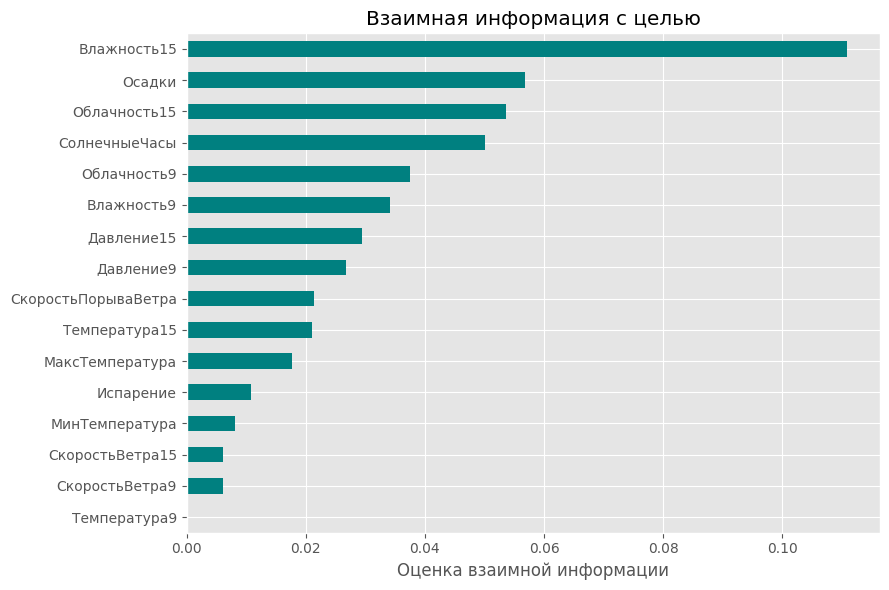

,Взаимная информация
Влажность15,0.1109
Осадки,0.0568
Облачность15,0.0536
СолнечныеЧасы,0.0500
Облачность9,0.0375
Влажность9,0.0341
Давление15,0.0294
Давление9,0.0268
СкоростьПорываВетра,0.0213
Температура15,0.0210


In [ ]:
mi_sample = X_train.sample(n=min(20000, len(X_train)), random_state=RANDOM_STATE)
mi_target = y_train.loc[mi_sample.index]
mi_values = mutual_info_classif(
    mi_sample, mi_target, discrete_features=False, random_state=RANDOM_STATE
)
mi_scores = pd.Series(mi_values, index=NUMERIC_COLS, name="Взаимная информация")
mi_scores.sort_values().plot.barh(
    figsize=(9, 6), color="teal", title="Взаимная информация с целью"
)
plt.xlabel("Оценка взаимной информации")
plt.tight_layout()
plt.show()
display(mi_scores.sort_values(ascending=False).to_frame())

Взаимная информация рассчитана на **20 000 случайно выбранных строках train** с фиксированным `random_state=42`. Подвыборка уменьшает время дополнительного анализа. Основные F-, RFE- и L1-селекторы ниже используют полный train, поэтому их наборы не ограничиваются этими 20 000 строками.

Лидирует `Влажность15` с оценкой около **0.1109**. Далее идут `Осадки` - **0.0568**, `Облачность15` - **0.0536** и `СолнечныеЧасы` - **0.0500**. Эти признаки несут заметную одномерную информацию о классе дождя. Порядок не полностью совпадает с F-критерием, поскольку критерии оценивают разные свойства зависимости.

У `Температура9` оценка равна нулю в показанном результате. Это результат работы оценивателя на выбранной подвыборке, а не доказательство строгой независимости и не запрет на использование этого признака в совместной модели. Действительно, далее RFE сохраняет `Температура9` в присутствии других входов.


## F-критерий и сравнение двух фильтров

Сравним корреляционный фильтр и `SelectKBest(f_classif, k=10)`. Первый оценивает повторы между входами, второй - одномерную связь каждого входа с целью. Число 10 задаёт бюджет количественной части.

In [ ]:
K_FEATURES = 10
f_selector = SelectKBest(score_func=f_classif, k=K_FEATURES).fit(X_train, y_train)
f_features = X_train.columns[f_selector.get_support()].tolist()
filter_comparison = pd.DataFrame([
    {"Метод": "Корреляция 0.90", "Числовых входов": len(corr_features),
     "Удалено": len(NUMERIC_COLS) - len(corr_features),
     "Размер полного train": str(assemble_dataset(train_scaled, corr_features).shape),
     "Размер полного test": str(assemble_dataset(test_scaled, corr_features).shape)},
    {"Метод": "F-критерий k=10", "Числовых входов": len(f_features),
     "Удалено": len(NUMERIC_COLS) - len(f_features),
     "Размер полного train": str(assemble_dataset(train_scaled, f_features).shape),
     "Размер полного test": str(assemble_dataset(test_scaled, f_features).shape)},
])
display(filter_comparison)
display(pd.DataFrame({
    "Корреляционный фильтр": [col in corr_features for col in NUMERIC_COLS],
    "F-критерий": [col in f_features for col in NUMERIC_COLS],
}, index=NUMERIC_COLS))

,Метод,Числовых входов,Удалено,Размер полного train,Размер полного test
0,Корреляция 0.90,13,3,"(113752, 20)","(28438, 20)"
1,F-критерий k=10,10,6,"(113752, 17)","(28438, 17)"


,Корреляционный фильтр,F-критерий
МинТемпература,True,False
МаксТемпература,True,False
Осадки,True,True
Испарение,True,False
СолнечныеЧасы,True,True
СкоростьПорываВетра,True,True
СкоростьВетра9,True,False
СкоростьВетра15,True,False
Влажность9,True,True
Влажность15,True,True


Получены две разные полные структуры:

| Подход | Количественных входов | Удалено | Всего столбцов с категориями, датой и целью |
|---|---:|---:|---:|
| Корреляция 0.90 | 13 | 3 | 20 |
| F-критерий, k=10 | 10 | 6 | 17 |

У корреляционного фильтра итоговые размеры **113 752 × 20** и **28 438 × 20**, у F-критерия - **113 752 × 17** и **28 438 × 17**. Число наблюдений и пять категориальных входов одинаковы.

F-критерий возвращает `Давление15` и `Температура15`, которые исключал корреляционный фильтр, но убирает ряд входов с меньшей одномерной связью с целью. Среди сохранённых F-фильтром есть и `Давление9`, и `Давление15`: одномерный критерий не запрещает избыточные пары.

Следовательно, два набора отвечают на разные вопросы. Корреляционный фильтр ограничивает повторы между входами, а F-фильтр выбирает десять входов по связи с целью.

## Влияние параметров отбора

Изменим корреляционный порог и число входов F-фильтра. Все решения принимаются только по train.

In [ ]:
settings_rows = []
for threshold in [0.85, 0.90, 0.95, 0.98]:
    columns, _ = correlation_filter(X_train, threshold)
    settings_rows.append({
        "Метод": "Корреляция", "Параметр": str(threshold),
        "Числовых осталось": len(columns), "Удалено": len(NUMERIC_COLS) - len(columns),
        "Состав": ", ".join(columns),
    })
for k in [6, 10, 13]:
    selector = SelectKBest(f_classif, k=k).fit(X_train, y_train)
    columns = X_train.columns[selector.get_support()].tolist()
    settings_rows.append({
        "Метод": "F-критерий", "Параметр": f"k={k}",
        "Числовых осталось": len(columns), "Удалено": len(NUMERIC_COLS) - len(columns),
        "Состав": ", ".join(columns),
    })
settings_comparison = pd.DataFrame(settings_rows)
display(settings_comparison)

,Метод,Параметр,Числовых осталось,Удалено,Состав
0,Корреляция,0.85,13,3,"МинТемпература, МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Ск..."
1,Корреляция,0.9,13,3,"МинТемпература, МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Ск..."
2,Корреляция,0.95,14,2,"МинТемпература, МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Ск..."
3,Корреляция,0.98,16,0,"МинТемпература, МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Ск..."
4,F-критерий,k=6,6,10,"Осадки, СолнечныеЧасы, Влажность9, Влажность15, Облачность9, Облачность15"
5,F-критерий,k=10,10,6,"Осадки, СолнечныеЧасы, СкоростьПорываВетра, Влажность9, Влажность15, Давление9, Давление15, Облачность9, О..."
6,F-критерий,k=13,13,3,"МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Влажность9, Влажно..."


При порогах корреляции **0.85** и **0.90** сохранено по **13** количественных входов. При **0.95** остаётся **14**, поскольку связь `Температура9` с `МинТемпература` около 0.9024 уже не превышает новый порог. При **0.98** остаются все **16** входов: ни одна из показанных пар не проходит условие удаления.

Таким образом, более строгий порог может уменьшать размерность, но изменения происходят ступенчато. Порог 0.98 для базового уровня не подходит как итоговый результат, поскольку в данном наборе не сокращает число входов. Порог 0.90 удаляет три выраженных повтора и оставляет большинство измерений.

Для F-критерия `k=6`, `k=10` и `k=13` дают соответственно 6, 10 и 13 количественных входов. При k=6 сохраняются `Осадки`, `СолнечныеЧасы`, `Влажность9`, `Влажность15`, `Облачность9`, `Облачность15`. Такой набор компактен, но полностью исключает давление и ветер, которые могут давать дополнительную информацию.

Для удаления только сильных линейных повторов более осторожным выглядит корреляционный порог 0.90. Для сокращения до десяти количественных входов F-фильтр даёт простую отправную точку, а RFE позволяет учесть совместное присутствие переменных в линейной модели.

# 2.3. Контроль корректности подготовки данных
## Метод-обёртка: RFE

Используем логистическую регрессию и рекурсивное исключение по одному количественному входу до десяти. Стандартизация уже выполнена, категории в эту численную модель не передаются.

In [ ]:
def make_logistic(C=1.0, penalty="l2"):
    return LogisticRegression(
        C=C, penalty=penalty, solver="liblinear",
        max_iter=3000, random_state=RANDOM_STATE,
    )

rfe_selector = RFE(
    estimator=make_logistic(), n_features_to_select=K_FEATURES, step=1
).fit(X_train, y_train)
rfe_features = X_train.columns[rfe_selector.get_support()].tolist()
rfe_report = pd.DataFrame({
    "Ранг RFE": rfe_selector.ranking_,
    "Сохранён": rfe_selector.get_support(),
}, index=NUMERIC_COLS)
display(rfe_report.sort_values("Ранг RFE"))
print("Сохранённые количественные входы:", rfe_features)

,Ранг RFE,Сохранён
МаксТемпература,1,True
Осадки,1,True
СкоростьПорываВетра,1,True
СолнечныеЧасы,1,True
СкоростьВетра15,1,True
Давление15,1,True
Давление9,1,True
Влажность15,1,True
Температура9,1,True
Облачность15,1,True


Сохранённые количественные входы: ['МаксТемпература', 'Осадки', 'СолнечныеЧасы', 'СкоростьПорываВетра', 'СкоростьВетра15', 'Влажность15', 'Давление9', 'Давление15', 'Облачность15', 'Температура9']


RFE последовательно исключал по одному входу, пока из 16 не осталось **10**. Ранг 1 получили `МаксТемпература`, `Осадки`, `СолнечныеЧасы`, `СкоростьПорываВетра`, `СкоростьВетра15`, `Влажность15`, `Давление9`, `Давление15`, `Облачность15` и `Температура9`.

Исключены шесть входов: `МинТемпература`, `Испарение`, `СкоростьВетра9`, `Влажность9`, `Облачность9`, `Температура15`. В отчёте ранг 2 у `Влажность9` означает, что этот вход был исключён последним перед достижением десяти колонок. Более высокий ранг отражает более раннее исключение, а не отдельную численную вероятность полезности.

Показательно, что RFE сохранил `Температура9`, хотя её одномерные оценки были невелики, и оставил оба измерения давления. Это не противоречие: решение принимается по коэффициентам модели при совместном присутствии входов, а не по изолированной связи каждого входа с целью. Но RFE с линейной моделью не учитывает произвольные нелинейные взаимодействия автоматически.


## Встроенный метод: L1-регуляризация

Обучим логистическую регрессию с L1 и выберем входы с модулем коэффициента не меньше `1e-5`. Рассмотрим влияние параметра C.

In [ ]:
l1_selector = SelectFromModel(
    estimator=make_logistic(C=0.01, penalty="l1"), threshold=1e-5
).fit(X_train, y_train)
l1_features = X_train.columns[l1_selector.get_support()].tolist()
l1_report = pd.DataFrame({
    "Коэффициент L1": l1_selector.estimator_.coef_.ravel(),
    "Сохранён": l1_selector.get_support(),
}, index=NUMERIC_COLS)
display(l1_report)
l1_rows = []
for value in [0.001, 0.01, 0.1, 1.0]:
    selector = SelectFromModel(
        make_logistic(C=value, penalty="l1"), threshold=1e-5
    ).fit(X_train, y_train)
    columns = X_train.columns[selector.get_support()].tolist()
    l1_rows.append({"C": value, "Числовых осталось": len(columns), "Состав": ", ".join(columns)})
l1_settings = pd.DataFrame(l1_rows)
display(l1_settings)

,Коэффициент L1,Сохранён
МинТемпература,0.0264,True
МаксТемпература,0.0000,False
Осадки,0.2074,True
Испарение,-0.0052,True
СолнечныеЧасы,-0.3056,True
СкоростьПорываВетра,0.6386,True
СкоростьВетра9,-0.0686,True
СкоростьВетра15,-0.1772,True
Влажность9,0.0955,True
Влажность15,1.1020,True


,C,Числовых осталось,Состав
0,0.0010,9,"Осадки, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра15, Влажность9, Влажность15, Давление15, Облачнос..."
1,0.0100,13,"МинТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, СкоростьВетра15, Вл..."
2,0.1000,16,"МинТемпература, МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Ск..."
3,1.0000,16,"МинТемпература, МаксТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, Ск..."


При `C=0.01` L1-отбор сохранил **13** количественных входов. Коэффициенты `МаксТемпература`, `Температура9` и `Температура15` обнулились, остальные прошли порог по модулю `1e-5`. Значения коэффициентов округлены только при выводе: решение селектора принималось по полной точности.

При `C=0.001` осталось **9** входов, при `C=0.01` - **13**, при `C=0.1` и `C=1.0` - все **16**. Значит, более сильная регуляризация в этих настройках даёт более компактный набор. При слабом штрафе встроенный метод уже не сокращает размерность данного датасета.

Большой по модулю коэффициент означает сильный линейный вклад при заданных остальных входах, но не обязательно причинное влияние. Положительный или отрицательный знак не делает вход автоматически полезным или бесполезным: для отбора важен модуль. Взаимная корреляция может распределять или перераспределять веса между похожими измерениями.

Использована схема из методических указаний: логистическая регрессия с `penalty="l1"`, solver `liblinear`, затем `SelectFromModel` и маска выбранных входов. В отличие от примера с C=1, взято C=0.01, поскольку при C=1 в наших результатах остаются все 16 количественных входов. Это обоснование сокращения размерности, а не доказательство наилучшего качества C=0.01.

## Сравнение фильтра, обёртки и встроенного метода

Сопоставим число входов, структуру полных таблиц и принадлежность каждого количественного признака выбранным наборам.

,Метод,Числовых осталось,Числовых удалено,Категорий сохранено,Размер полного train,Размер полного test,Количественные признаки
0,Фильтр: F k=10,10,6,5,"(113752, 17)","(28438, 17)","Осадки, СолнечныеЧасы, СкоростьПорываВетра, Влажность9, Влажность15, Давление9, Давление15, Облачность9, О..."
1,Обёртка: RFE k=10,10,6,5,"(113752, 17)","(28438, 17)","МаксТемпература, Осадки, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра15, Влажность15, Давление9, Давл..."
2,Встроенный: L1 C=0.01,13,3,5,"(113752, 20)","(28438, 20)","МинТемпература, Осадки, Испарение, СолнечныеЧасы, СкоростьПорываВетра, СкоростьВетра9, СкоростьВетра15, Вл..."


,Фильтр: F k=10,Обёртка: RFE k=10,Встроенный: L1 C=0.01
МинТемпература,False,False,True
МаксТемпература,False,True,False
Осадки,True,True,True
Испарение,False,False,True
СолнечныеЧасы,True,True,True
СкоростьПорываВетра,True,True,True
СкоростьВетра9,False,False,True
СкоростьВетра15,False,True,True
Влажность9,True,False,True
Влажность15,True,True,True


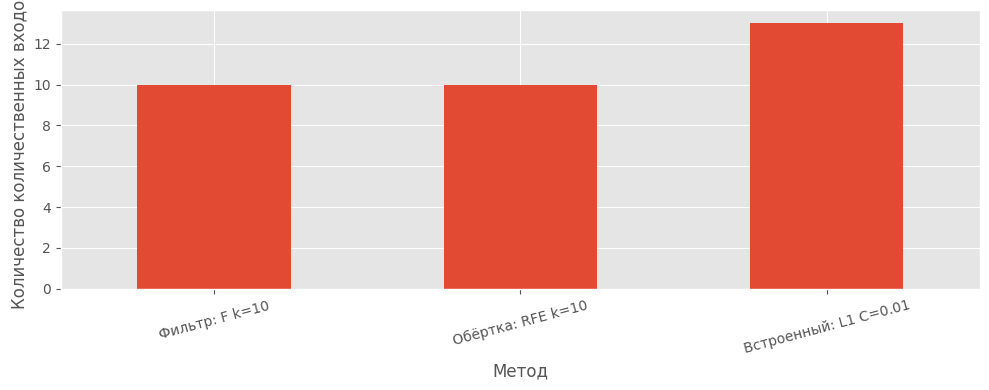

In [ ]:
selected_sets = {
    "Фильтр: F k=10": f_features,
    "Обёртка: RFE k=10": rfe_features,
    "Встроенный: L1 C=0.01": l1_features,
}
methods_comparison = pd.DataFrame([
    {"Метод": name, "Числовых осталось": len(columns),
     "Числовых удалено": len(NUMERIC_COLS) - len(columns),
     "Категорий сохранено": len(CATEGORY_COLS),
     "Размер полного train": str(assemble_dataset(train_scaled, columns).shape),
     "Размер полного test": str(assemble_dataset(test_scaled, columns).shape),
     "Количественные признаки": ", ".join(columns)}
    for name, columns in selected_sets.items()
])
selection_matrix = pd.DataFrame({
    name: [col in columns for col in NUMERIC_COLS]
    for name, columns in selected_sets.items()
}, index=NUMERIC_COLS)
display(methods_comparison)
display(selection_matrix)
methods_comparison.plot.bar(
    x="Метод", y="Числовых осталось", legend=False, figsize=(10, 4), rot=15
)
plt.ylabel("Количество количественных входов")
plt.tight_layout()
plt.show()

Три группы методов применены и дали следующие результаты:

- **F-критерий**: сохранено 10 количественных входов, удалено 6, полные таблицы имеют 17 столбцов.
- **RFE**: сохранено 10 количественных входов, удалено 6, полные таблицы также имеют 17 столбцов.
- **L1 при C=0.01**: сохранено 13 количественных входов, удалено 3, полные таблицы имеют 20 столбцов.

В каждом варианте сохранены все пять категориальных входов, дата и цель. Следовательно, сравнение не смешивает удаление количественных входов с предварительным исключением текстовых столбцов.

F и RFE имеют **семь** общих количественных входов: `Осадки`, `СолнечныеЧасы`, `СкоростьПорываВетра`, `Влажность15`, `Давление9`, `Давление15` и `Облачность15`. Только F сохраняет `Влажность9`, `Облачность9` и `Температура15`, только RFE - `МаксТемпература`, `СкоростьВетра15` и `Температура9`. Поэтому для точного сравнения состава следует ориентироваться на таблицу масок, а не только на одинаковое число столбцов.


## Анализ категориальных признаков

Для каждого категориального входа построим таблицу сопряжённости с целью и вычислим скорректированный V Крамера. Это мера связи на основе частот, не требующая замены исходных категорий числами в датасете.

Критерий независимости рассчитывается по неотрицательным частотам. При большом объёме данных малое p-value не означает сильную прогнозную связь. Если ожидаемые частоты малы, приближение критерия требует осторожности. Категории по этому описательному анализу не исключаются.

,Признак,Категорий,"V Крамера, скорр.",p-value,Ячеек с ожидаемой частотой <5
4,ДождьСегодня,2,0.3053,0.0000,0
0,Место,49,0.1541,0.0000,0
2,НаправлениеВетра9,16,0.1153,0.0000,0
1,НаправлениеПорываВетра,16,0.1064,0.0000,0
3,НаправлениеВетра15,16,0.0926,0.0000,0


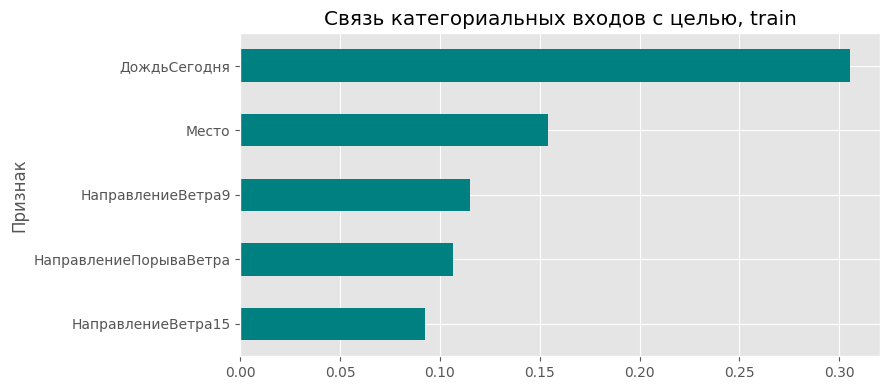

In [ ]:
category_rows = []
for col in CATEGORY_COLS:
    table = pd.crosstab(train_scaled[col], y_train)
    if min(table.shape) < 2:
        category_rows.append({
            "Признак": col, "Категорий": table.shape[0],
            "V Крамера, скорр.": np.nan, "p-value": np.nan,
            "Ячеек с ожидаемой частотой <5": np.nan,
        })
        continue
    statistic, p_value, _, expected = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    r, k = table.shape
    phi_corrected = max(0, statistic / n - (k - 1) * (r - 1) / (n - 1))
    r_corrected = r - (r - 1) ** 2 / (n - 1)
    k_corrected = k - (k - 1) ** 2 / (n - 1)
    denominator = min(r_corrected - 1, k_corrected - 1)
    value = np.sqrt(phi_corrected / denominator) if denominator > 0 else np.nan
    category_rows.append({
        "Признак": col, "Категорий": r,
        "V Крамера, скорр.": value, "p-value": p_value,
        "Ячеек с ожидаемой частотой <5": int((expected < 5).sum()),
    })
category_report = pd.DataFrame(category_rows).sort_values("V Крамера, скорр.", ascending=False)
display(category_report)

category_report.sort_values("V Крамера, скорр.").plot.barh(
    x="Признак", y="V Крамера, скорр.", legend=False,
    figsize=(9, 4), color="teal", title="Связь категориальных входов с целью, train"
)
plt.tight_layout()
plt.show()

Категориальные входы исследованы по таблицам сопряжённости с целью, без замены значений в датасете числовыми кодами. Наибольший скорректированный V Крамера получен у `ДождьСегодня` - **0.3053**. Далее идут `Место` - **0.1541**, `НаправлениеВетра9` - **0.1153**, `НаправлениеПорываВетра` - **0.1064**, `НаправлениеВетра15` - **0.0926**.

Это означает, что среди рассмотренных категорий наиболее выраженная одномерная связь с дождём завтра наблюдается у факта дождя сегодня. Значения V не являются процентами точности, не доказывают причинную связь и не показывают, насколько категория улучшит уже обученную модель с другими входами.

Количество категорий соответствует смыслу полей: у `Место` - **49** значений, у каждого направления ветра - **16**, у `ДождьСегодня` - **2**. Для всех построенных таблиц число ячеек с ожидаемой частотой ниже 5 равно нулю. Это снимает именно проблему редких ожидаемых частот в данном расчёте, но не доказывает полную независимость наблюдений во времени и между станциями.

Во всех строках p-value напечатано как `0.0000`, это результат округления очень малых значений, а не достаточное основание объявить все входы одинаково сильными. Скорректированный V помогает сравнить величину связи, учитывая часть смещения из-за числа категорий.


## Формирование итоговой выборки



In [ ]:
FINAL_METHOD = "Пересечение F-критерия, RFE и L1"

common_features = (
    set(f_features)
    & set(rfe_features)
    & set(l1_features)
)

final_features = [
    col for col in NUMERIC_COLS
    if col in common_features
]

if not final_features:
    raise ValueError(
        " "
    )

train_final = assemble_dataset(train_scaled, final_features)
test_final = assemble_dataset(test_scaled, final_features)

print("Метод:", FINAL_METHOD)
print("Количественных признаков до:", len(NUMERIC_COLS))
print("Количественных признаков после:", len(final_features))
print("Удалено:", len(NUMERIC_COLS) - len(final_features))
print("Общие признаки:", final_features)
print("Размер train:", train_final.shape)
print("Размер test: ", test_final.shape)

display(train_final.head())

Метод: Пересечение F-критерия, RFE и L1
Количественных признаков до: 16
Количественных признаков после: 7
Удалено: 9
Общие признаки: ['Осадки', 'СолнечныеЧасы', 'СкоростьПорываВетра', 'Влажность15', 'Давление9', 'Давление15', 'Облачность15']
Размер train: (113752, 14)
Размер test:  (28438, 14)


,Дата,Место,Осадки,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,НаправлениеВетра15,Влажность15,Давление9,Давление15,Облачность15,ДождьСегодня,ДождьЗавтра
0,2007-11-02,Canberra,0.1406,0.5931,ENE,-0.0699,E,W,-0.7495,-0.7751,-1.0249,-0.7303,Yes,Yes
1,2007-11-03,Canberra,0.1406,-1.6719,NW,3.4203,N,NNE,0.8468,-1.2040,-1.2043,1.0367,Yes,Yes
2,2007-11-04,Canberra,4.3455,0.3807,NW,1.0682,WNW,W,0.2180,-1.7957,-1.2342,1.0367,Yes,Yes
3,2007-11-05,Canberra,0.0476,0.9116,SSE,0.7647,SSE,ESE,-0.1206,0.0977,0.4847,1.0367,Yes,No
4,2007-11-06,Canberra,-0.2776,0.0622,SE,0.3095,SE,E,0.2663,0.9112,0.9630,0.1532,No,No


## Контроль корректности и сравнение до/после

Проверим число строк, порядок наблюдений, совпадение категорий, даты, цели и выбранных количественных значений. Отдельно покажем структуру каждой колонки итоговой таблицы.

In [ ]:
assert 0 < len(final_features) < len(NUMERIC_COLS)
for source, result in [(train_scaled, train_final), (test_scaled, test_final)]:
    assert len(result) == len(source)
    assert result.index.equals(source.index)
    assert result[CATEGORY_COLS + [DATE_COL, TARGET_COL]].equals(
        source[CATEGORY_COLS + [DATE_COL, TARGET_COL]]
    )
    assert result[final_features].equals(source[final_features])
    assert not result.isna().any().any()
    assert np.isfinite(result[final_features].to_numpy()).all()
assert list(train_final.columns) == list(test_final.columns)
assert np.allclose(train_final[final_features].mean(), 0, atol=1e-7)
assert np.allclose(train_final[final_features].std(ddof=0), 1, atol=1e-7)

def quality_report(frame, name):
    columns = [col for col in frame.select_dtypes(include="number").columns
               if col not in [DATE_COL, TARGET_COL]]
    return {
        "Версия": name, "Строк": len(frame), "Количественных входов": len(columns),
        "Категориальных входов": len(CATEGORY_COLS), "Служебных дат": 1,
        "Целевых столбцов": 1, "Всего столбцов": frame.shape[1],
        "Пропусков": int(frame.isna().sum().sum()),
        "Бесконечных числовых": int(np.isinf(frame[columns].to_numpy()).sum()),
    }
quality_comparison = pd.DataFrame([
    quality_report(train_scaled, "Train до отбора"),
    quality_report(train_final, "Train после отбора"),
    quality_report(test_scaled, "Test до отбора"),
    quality_report(test_final, "Test после отбора"),
])
display(quality_comparison)
final_structure = pd.DataFrame({
    "Столбец": train_final.columns, "Тип": train_final.dtypes.astype(str).to_numpy(),
})
final_structure["Роль"] = final_structure["Столбец"].map(
    lambda col: "Цель" if col == TARGET_COL else "Служебная дата" if col == DATE_COL
    else "Категориальный вход" if col in CATEGORY_COLS else "Масштабированный количественный вход"
)
display(final_structure)
print("Проверки пройдены: строки, категории, дата, цель и числовые значения сохранены.")

,Версия,Строк,Количественных входов,Категориальных входов,Служебных дат,Целевых столбцов,Всего столбцов,Пропусков,Бесконечных числовых
0,Train до отбора,113752,16,5,1,1,23,0,0
1,Train после отбора,113752,7,5,1,1,14,0,0
2,Test до отбора,28438,16,5,1,1,23,0,0
3,Test после отбора,28438,7,5,1,1,14,0,0


,Столбец,Тип,Роль
0,Дата,object,Служебная дата
1,Место,object,Категориальный вход
2,Осадки,float64,Масштабированный количественный вход
3,СолнечныеЧасы,float64,Масштабированный количественный вход
4,НаправлениеПорываВетра,object,Категориальный вход
5,СкоростьПорываВетра,float64,Масштабированный количественный вход
6,НаправлениеВетра9,object,Категориальный вход
7,НаправлениеВетра15,object,Категориальный вход
8,Влажность15,float64,Масштабированный количественный вход
9,Давление9,float64,Масштабированный количественный вход


Проверки пройдены: строки, категории, дата, цель и числовые значения сохранены.


Проверки выполнены без ошибок. Количество строк сохранено: **113 752 в train** и **28 438 в test**. Число количественных входов уменьшилось с **16 до 10**, а общее число столбцов с **23 до 17**. Все пять категорий остаются в обеих частях.

Проверены не только размеры: `equals` подтверждает точное совпадение значений категорий, даты, цели и выбранных количественных столбцов с исходными таблицами. Индексы и порядок наблюдений тоже сохранены. Это исключает случайное смещение строк при сборке результата.

Пропусков и бесконечных количественных значений нет до и после отбора. На train выбранные входы по-прежнему имеют среднее около нуля и единичное отклонение, поскольку их значения не изменялись.

## Сохранение результатов

Сохраним полные итоговые CSV.

In [ ]:
OUTPUT_DIR = Path("data_selected")
OUTPUT_DIR.mkdir(exist_ok=True)

train_final.to_csv(
    OUTPUT_DIR / "weatherAUS_train_selected_scaled_with_categories.csv",
    index=False,
    encoding="utf-8-sig",
)

test_final.to_csv(
    OUTPUT_DIR / "weatherAUS_test_selected_scaled_with_categories.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Метод отбора:", FINAL_METHOD)
print("Сохранён train:", train_final.shape)
print("Сохранён test: ", test_final.shape)

Метод отбора: Пересечение F-критерия, RFE и L1
Сохранён train: (113752, 14)
Сохранён test:  (28438, 14)


# Итог

Отбор признаков выполнен после очистки и масштабирования данных. Исходная выборка содержала 16 количественных и 5 категориальных входов. Категориальные признаки сохранены без кодирования. Дата оставлена служебным столбцом, а целевая переменная не включалась в состав входных признаков. На базовом уровне корреляционный фильтр выявил сильно связанные количественные измерения. Анализ исключённых признаков показал, что избыточность не означает полного отсутствия полезной информации. Затем были применены три метода отбора: F-критерий, рекурсивное исключение RFE и встроенный L1-отбор. Итоговый набор количественных входов сформирован как пересечение результатов этих трёх методов. Признак сохранялся только при выборе всеми тремя методами, а отсутствие хотя бы в одном наборе приводило к его исключению. Такой подход позволяет выделить признаки, получившие согласованную оценку разных методов, и сократить размерность выборки. При этом пересечение может исключить полезную информацию и не гарантирует наилучшего прогнозного качества. Все селекторы обучались только на train, а одинаковый список колонок применён к train и test с сохранением категорий, даты, цели и масштабированных значений выбранных входов. Итоговые выборки предназначены для дальнейших лабораторных с обработкой текстовых входов либо использованием модели с нативной поддержкой категорий и последующей проверкой качества.